# **Problem Statement**

---

#### **Business Context**
Last Mile Delivery is the final and most expensive stage of the logistics chain: moving a package from the local station to the customer's door. It typically accounts for the largest share of total shipping costs and is the stage that most directly shapes the customer experience, since it determines whether the delivery promise is met.

This project focuses on Last Mile operations in **Shanghai**, one of the densest and most complex commercial hubs in the world. Delivery times there are affected by geographic factors (zone, distance, type of area) and temporal factors (time of day, day of the week, peak hours). Being able to anticipate how long a delivery will take allows the company to set realistic delivery promises, plan fleet capacity and identify critical zones and time windows.

The data comes from **LaDe (Last-mile Delivery dataset)**, published by Cainiao, the logistics arm of Alibaba. It covers **6 months of operations**, with **1,483,864 orders** and **17 columns**, handled by **1,733 couriers** across **52 regions** of the city. The dataset has no null values and no duplicated orders, and GPS coordinates are anonymized with an approximation radius of about 10 meters.

---

#### **Objective**
The goal is to build a **supervised regression model** that predicts the **delivery time in minutes** (`tiempo_entrega_min`) of each order, measured from the moment the courier accepts the task (`accept_time`) until the package is delivered (`delivery_time`).

With this model, the company aims to:
1. Provide more accurate delivery time estimates to customers.
2. Understand which geographic and temporal factors have the greatest impact on delivery times.
3. Support operational decisions such as courier allocation, workload planning by time window and focus on critical zones.

To achieve this, we clean the data, engineer new features (distance, speed, courier experience, time of day, day of the week), explore the relationships with the target, and train and evaluate regression models using RMSE, MAE, R² and Adjusted R².

---

#### **Data Dictionary**
Each row of the dataset represents a single delivery order. The original attributes are:

1. **Order Information**
   - **order_id:** Unique identifier of each package.
   - **ds:** Date of the order (format MMDD).

2. **Location Information**
   - **city:** City where the delivery takes place (Shanghai).
   - **region_id:** Identifier of the region.
   - **aoi_id:** Identifier of the Area of Interest (AOI) where the package is delivered.
   - **aoi_type:** Type of AOI (categorical code, e.g. residential, commercial, school).
   - **lng / lat:** Coordinates of the package's delivery location.

3. **Courier Information**
   - **courier_id:** Unique identifier of the courier.

4. **Task Events**
   - **accept_time:** Date and time when the courier accepts the task (format MM-DD HH:MM:SS).
   - **accept_gps_time:** Date and time of the GPS point closest to the acceptance time.
   - **accept_gps_lng / accept_gps_lat:** Coordinates of the courier when accepting the task.
   - **delivery_time:** Date and time when the courier completes the delivery (format MM-DD HH:MM:SS).
   - **delivery_gps_time:** Date and time of the GPS point closest to the delivery time.
   - **delivery_gps_lng / delivery_gps_lat:** Coordinates of the courier when completing the delivery.

5. **Target Variable (engineered)**
   - **tiempo_entrega_min:** Delivery time in minutes, calculated as `delivery_time - accept_time`.

## **Importing necessary libraries**

In [100]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder

# Models
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# To check model performance
from sklearn.metrics import make_scorer,mean_squared_error, r2_score, mean_absolute_error

## **Loading the data**

In [102]:
# Data import
def get_my_data():
    url = "https://huggingface.co/datasets/Cainiao-AI/LaDe/resolve/main/delivery/delivery_sh.csv"
    df = pd.read_csv(url)
    return df
df = get_my_data()

In [103]:
# View the first 5 rows of the dataset
df.head()

,order_id,region_id,city,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_time,accept_gps_lng,accept_gps_lat,delivery_time,delivery_gps_time,delivery_gps_lng,delivery_gps_lat,ds
0,3158819,1,Shanghai,164,121.52128,31.06614,450,1,06-04 11:05:00,06-04 11:05:00,121.52281,31.10598,06-04 17:40:00,06-04 17:40:00,121.52407,31.06614,604
1,751342,1,Shanghai,164,121.52124,31.06687,450,1,06-04 11:18:00,06-04 11:18:00,121.52286,31.10599,06-04 15:06:00,06-04 15:06:00,121.52412,31.06618,604
2,3380476,1,Shanghai,164,121.52106,31.06731,450,1,06-03 10:13:00,06-03 10:13:00,121.52285,31.10591,06-03 15:11:00,06-03 15:11:00,121.52059,31.06672,603
3,2184571,1,Shanghai,164,121.52128,31.06616,450,1,06-04 10:39:00,06-04 10:39:00,121.52282,31.10593,06-04 15:41:00,06-04 15:41:00,121.52280,31.10542,604
4,941371,1,Shanghai,164,121.52123,31.06614,450,1,06-04 11:18:00,06-04 11:18:00,121.52285,31.10593,06-04 14:07:00,06-04 14:07:00,121.52290,31.06758,604


## **Data Overview**

#### **Data types**

In [104]:
# Shape of the dataset
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.\n")

# Column names, non-null counts and data types
df.info()

The dataset has 1483864 rows and 17 columns.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1483864 entries, 0 to 1483863
Data columns (total 17 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           1483864 non-null  int64  
 1   region_id          1483864 non-null  int64  
 2   city               1483864 non-null  object 
 3   courier_id         1483864 non-null  int64  
 4   lng                1483864 non-null  float64
 5   lat                1483864 non-null  float64
 6   aoi_id             1483864 non-null  int64  
 7   aoi_type           1483864 non-null  int64  
 8   accept_time        1483864 non-null  object 
 9   accept_gps_time    1483864 non-null  object 
 10  accept_gps_lng     1483864 non-null  float64
 11  accept_gps_lat     1483864 non-null  float64
 12  delivery_time      1483864 non-null  object 
 13  delivery_gps_time  1483864 non-null  object 
 14  delivery_gps_lng   1483864 non-null 

In [105]:
# Number of unique values per column (sorted from highest to lowest)
resumen_unicos = pd.DataFrame({
    'column': df.columns,
    'unique_values': [df[col].nunique() for col in df.columns]
})

resumen_unicos.sort_values(by='unique_values', ascending=False).reset_index(drop=True)

,column,unique_values
0,order_id,1483864
1,delivery_gps_time,144334
2,delivery_time,144334
3,accept_gps_time,130836
4,accept_time,130836
5,delivery_gps_lng,73503
6,lng,68747
7,delivery_gps_lat,58280
8,lat,56161
9,aoi_id,15564


##### **Observations:**
<small><font color="gray">Data types</font></small>

- The dataset has 1,483,864 rows and 17 columns. Each row is a single delivery order.
- 6 columns are int64, 6 are float64 and 5 are text (object).
- `order_id`, `region_id`, `courier_id`, `aoi_id` and `aoi_type` are stored as integers, but they are identifiers or category codes, not quantities.
- `order_id` has one unique value per row, so it identifies each order.
- `city` has a single value (Shanghai), so it does not add information to the model.
- There are 52 regions, 16 AOI types, 15,564 AOIs and 1,733 couriers.
- `ds` has 184 unique values, which confirms that the data covers about 6 months of operations.
- The delivery coordinates (`lng`, `lat`, `delivery_gps_*`) have between 56,000 and 74,000 unique values, while the acceptance coordinates (`accept_gps_*`) have only about 1,250. This means that couriers accept their orders from a small number of fixed locations (stations or depots).
- The time columns (`accept_time`, `accept_gps_time`, `delivery_time`, `delivery_gps_time`) are stored as text in the format MM-DD HH:MM:SS, without the year. We need to convert them to datetime to calculate the delivery time.

#### **Statistical summary**

In [106]:
# Statistical summary of the numerical columns (transposed for readability)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
order_id,1483864.0,2.256844e+06,1.303169e+06,2.00000,1.128599e+06,2.256111e+06,3.385764e+06,4.514655e+06
region_id,1483864.0,4.575173e+01,2.716011e+01,1.00000,2.200000e+01,4.500000e+01,6.900000e+01,1.600000e+02
courier_id,1483864.0,2.430808e+03,1.373688e+03,0.00000,1.314000e+03,2.411000e+03,3.617000e+03,4.874000e+03
lng,1483864.0,1.214720e+02,1.413028e-01,102.08492,1.213992e+02,1.214838e+02,1.215417e+02,1.219547e+02
lat,1483864.0,3.119236e+01,1.084289e-01,26.69903,3.114591e+01,3.120879e+01,3.125087e+01,3.991190e+01
aoi_id,1483864.0,3.024220e+04,1.728783e+04,1.00000,1.521800e+04,3.024800e+04,4.503900e+04,6.014700e+04
aoi_type,1483864.0,3.379326e+00,4.905149e+00,0.00000,1.000000e+00,1.000000e+00,1.000000e+00,1.500000e+01
accept_gps_lng,1483864.0,1.214724e+02,1.314692e-01,106.50668,1.214001e+02,1.214739e+02,1.215308e+02,1.218647e+02
accept_gps_lat,1483864.0,3.119154e+01,1.037831e-01,29.58773,3.113889e+01,3.120761e+01,3.125623e+01,3.141069e+01
delivery_gps_lng,1483864.0,1.214640e+02,9.402852e-01,-0.00009,1.213991e+02,1.214835e+02,1.215423e+02,1.219749e+02


##### **Observations:**
<small><font color="gray">Statistical summary</font></small>

- The statistics of `order_id`, `region_id`, `courier_id` and `aoi_id` have no meaning, since they are identifiers.
- `aoi_type` goes from 0 to 15, with a median of 1. Most orders are delivered to the same type of area.
- `ds` goes from 501 to 1031, which confirms that the data covers 6 months of operations (May to October).
- 50% of the coordinates are between longitude 121.40–121.54 and latitude 31.15–31.25, which matches Shanghai.
- However, some coordinates are far outside the city: `lng` has a minimum of 102.08 and `lat` has a maximum of 39.91.
- `delivery_gps_lng` and `delivery_gps_lat` have a minimum of about 0, which means some GPS points were not recorded correctly. We treat these invalid coordinates in the data cleaning stage.

#### **Missing values**

In [107]:
# Number of missing values per column
df.isnull().sum()

order_id             0
region_id            0
city                 0
courier_id           0
lng                  0
lat                  0
aoi_id               0
aoi_type             0
accept_time          0
accept_gps_time      0
accept_gps_lng       0
accept_gps_lat       0
delivery_time        0
delivery_gps_time    0
delivery_gps_lng     0
delivery_gps_lat     0
ds                   0
dtype: int64

##### **Observations:**
<small><font color="gray">Missing values</font></small>

- There are no missing values in any of the 17 columns, so no imputation is needed.
- Even so, some columns contain invalid values (such as GPS coordinates equal to 0), which we treat later in the data cleaning stage.

#### **Duplicates and constant columns**

In [108]:
# Exact duplicate rows (all columns)
print(f"Exact duplicate rows: {df.duplicated().sum()}")

# Duplicate order IDs
print(f"Duplicate order IDs: {df['order_id'].duplicated().sum()}")

# Duplicate columns: the GPS time columns look identical to the event time columns
print(f"accept_time equals accept_gps_time: {df['accept_time'].equals(df['accept_gps_time'])}")
print(f"delivery_time equals delivery_gps_time: {df['delivery_time'].equals(df['delivery_gps_time'])}")

Exact duplicate rows: 0
Duplicate order IDs: 0
accept_time equals accept_gps_time: True
delivery_time equals delivery_gps_time: True


In [109]:
# Drop the duplicated columns and the constant column (city has a single value)
# We check that the columns exist, to avoid an error if the cell is run twice
columns_to_drop = ['accept_gps_time', 'delivery_gps_time', 'city']

existing_columns = [col for col in columns_to_drop if col in df.columns]

if existing_columns:
    df.drop(columns=existing_columns, inplace=True)
    print(f"Dropped columns: {existing_columns}")
else:
    print("The columns are no longer in the dataset")

print(f"\nShape after dropping columns: {df.shape}")

Dropped columns: ['accept_gps_time', 'delivery_gps_time', 'city']

Shape after dropping columns: (1483864, 14)


##### **Observations:**
<small><font color="gray">Duplicates and constant columns</font></small>

- There are no duplicate rows and every `order_id` is unique, so each row is a different order.
- However, `accept_gps_time` is identical to `accept_time`, and `delivery_gps_time` is identical to `delivery_time`.
- We dropped `accept_gps_time` and `delivery_gps_time` because they are redundant, and `city` because it has a single value.
- The dataset now has 1,483,864 rows and 14 columns.

## **Feature Engineering**

We create the new variables before the data cleaning and the EDA, because:
- The target variable (`tiempo_entrega_min`) is not in the original dataset, so we need to calculate it first.
- The data cleaning filters use some of the new variables (delivery time, distance and speed).
- We want to analyze the new variables in the EDA, to understand their relationship with the delivery time.

#### **Target variable: tiempo_entrega_min**

In [110]:
# Convert the time columns to datetime
# The dataset does not include the year, so we add it (2022, according to the dataset metadata)
df['accept_time'] = pd.to_datetime('2022-' + df['accept_time'], format='%Y-%m-%d %H:%M:%S')
df['delivery_time'] = pd.to_datetime('2022-' + df['delivery_time'], format='%Y-%m-%d %H:%M:%S')

# Target variable: delivery time in minutes, from acceptance to delivery
df['tiempo_entrega_min'] = (df['delivery_time'] - df['accept_time']).dt.total_seconds() / 60

In [111]:
# Range of delivery dates
min_delivery = df['delivery_time'].min()
max_delivery = df['delivery_time'].max()
print(f"Delivery dates go from {min_delivery} to {max_delivery}")

Delivery dates go from 2022-05-01 08:33:00 to 2022-11-16 23:09:00


In [112]:
# Statistical summary of the target variable
print(df['tiempo_entrega_min'].describe())

count    1.483864e+06
mean     1.111406e+02
std      2.191312e+02
min      0.000000e+00
25%      4.300000e+01
50%      7.200000e+01
75%      1.190000e+02
max      4.773900e+04
Name: tiempo_entrega_min, dtype: float64


##### **Observations:**
<small><font color="gray">Target variable</font></small>

- Delivery dates go from 2022-05-01 to 2022-11-16.
- The median delivery time is 72 minutes, and 50% of the orders are delivered between 43 and 119 minutes.
- The mean (111 minutes) is much higher than the median and the standard deviation is very high (219 minutes), so the target is strongly right-skewed.
- The minimum is 0 minutes and the maximum is 47,739 minutes (about 33 days). These values are not plausible for a last mile delivery, and we treat them in the data cleaning stage.

#### **Distance and speed: distancia_km, velocidad_kmh**

In [113]:
# Haversine distance: straight-line distance between two points on the Earth's surface
def haversine(lat1, lng1, lat2, lng2):
    R = 6371  # Earth's radius in km
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat, dlng = lat2 - lat1, lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlng/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# Distance between the courier's position when accepting the task and when delivering the package
df['distancia_km'] = haversine(
    df['accept_gps_lat'], df['accept_gps_lng'],
    df['delivery_gps_lat'], df['delivery_gps_lng']
)

# Implied average speed of the delivery
df['velocidad_kmh'] = df['distancia_km'] / (df['tiempo_entrega_min'] / 60)

##### **Observations:**
<small><font color="gray">Distance and speed</font></small>

- `distancia_km` is the straight-line distance between the courier's position when accepting the task and when delivering the package. The real route is longer, but this distance is a good proxy of how far the courier has to travel.
- `velocidad_kmh` is the implied average speed of the delivery. We use it only to detect inconsistent records in the data cleaning stage and in the EDA.
- `velocidad_kmh` is calculated with the target, so we do not use it as a feature in the model (it would cause data leakage).

#### **Courier experience: experiencia_courier**

In [114]:
# Courier experience: number of orders the courier had already accepted BEFORE the current order
# It only uses past orders of the same courier, to avoid temporal data leakage

# Sort by courier and acceptance time
df = df.sort_values(['courier_id', 'accept_time'])

# Cumulative count of previous orders of the courier (excluding the current order)
df['experiencia_courier'] = df.groupby('courier_id').cumcount()

##### **Observations:**
<small><font color="gray">Courier experience</font></small>

- `courier_id` has 1,733 values, so it cannot be used directly in the model. Instead, we use `experiencia_courier` to capture the courier's experience.
- The first order of each courier has an experience of 0, and the value increases with each new order.
- It only uses information available at the moment of the order, so it does not cause data leakage.

#### **Time features: hora_dia, dia_semana, es_finde**

In [115]:
# Time features extracted from the acceptance time
df['hora_dia'] = df['accept_time'].dt.hour                    # hour of the day (0-23)
df['dia_semana'] = df['accept_time'].dt.dayofweek             # day of the week (0 = Monday, 6 = Sunday)
df['es_finde'] = df['dia_semana'].isin([5, 6]).astype(int)    # 1 if Saturday or Sunday, 0 otherwise

##### **Observations:**
<small><font color="gray">Time features</font></small>

- `accept_time` is a timestamp and cannot be used directly in the model, so we extract the hour of the day, the day of the week and whether it is a weekend.
- These variables allow us to analyze peak hours and differences between weekdays and weekends in the EDA.
- They replace `ds` and `accept_time` as features in the model.

## **Data Cleaning**

The dataset has no missing values or duplicates, but it contains records that are not plausible for a last mile delivery: delivery times of 0 minutes or of several days, impossible speeds and coordinates outside Shanghai. These records would distort the EDA and the model, so we remove them.

Each filter is defined as a mask over the original dataset, so we can see how many rows each one removes. At the end, we apply all the filters together.

#### **Filter 1: Positive delivery time**

In [116]:
# Filter 1: keep only orders with a positive delivery time
n0 = len(df)
mask_tiempo_positivo = df['tiempo_entrega_min'] > 0
print(f"Filter time > 0: removes {n0 - mask_tiempo_positivo.sum()} rows")

Filter time > 0: removes 3148 rows


##### **Observations:**
<small><font color="gray">Filter 1: Positive delivery time</font></small>

- This filter removes 3,148 rows (0.2% of the dataset).
- The minimum delivery time is 0, so all these orders were delivered in the same minute they were accepted. This is not possible and most likely a recording error.

#### **Filter 2: Reasonable delivery time (up to 24 hours)**

In [117]:
# Filter 2: keep only orders delivered within 24 hours (1,440 minutes)
mask_24hs = df['tiempo_entrega_min'] <= 1440
print(f"Filter <= 24 hours: removes {n0 - mask_24hs.sum()} rows")

Filter <= 24 hours: removes 3578 rows


##### **Observations:**
<small><font color="gray">Filter 2: Reasonable delivery time</font></small>

- This filter removes 3,578 rows (0.2% of the dataset).
- A last mile delivery is expected to be completed within the same day. Times of several days (up to 33 days) are probably orders that were not delivered on the first attempt or were closed late in the system.

#### **Filter 3: Reasonable implied speed**

In [118]:
# Filter 3: keep only orders with a reasonable implied speed (between 0.5 and 60 km/h)
# We also keep orders with a distance below 50 meters: these are usually deliveries in the same building,
# where a long time over a short distance gives a very low speed
mask_velocidad = df['velocidad_kmh'].between(0.5, 60) | (df['distancia_km'] < 0.05)
print(f"Filter reasonable speed: removes {n0 - mask_velocidad.sum()} rows")

Filter reasonable speed: removes 206013 rows


##### **Observations:**
<small><font color="gray">Filter 3: Reasonable implied speed</font></small>

- This filter removes 206,013 rows (13.9% of the dataset). It is the filter that removes the most records.
- A speed above 60 km/h is not realistic for a courier in urban traffic, and usually comes from GPS errors.
- A speed below 0.5 km/h means the courier barely moved during the whole delivery time, so the time does not reflect the trip.
- We keep orders with a distance below 50 meters, because they are deliveries in the same building or very close to the acceptance point, where a low speed is normal.

#### **Filter 4: Coordinates inside Shanghai**

In [119]:
# Filter 4: keep only orders with all coordinates inside Shanghai (approximate bounding box)
bbox_lat = (30.6, 31.9)
bbox_lng = (120.8, 122.2)

mask_bbox = (
    df['lat'].between(*bbox_lat) & df['lng'].between(*bbox_lng) &
    df['accept_gps_lat'].between(*bbox_lat) & df['accept_gps_lng'].between(*bbox_lng) &
    df['delivery_gps_lat'].between(*bbox_lat) & df['delivery_gps_lng'].between(*bbox_lng)
)
print(f"Filter Shanghai bounding box: removes {n0 - mask_bbox.sum()} rows")

Filter Shanghai bounding box: removes 316 rows


##### **Observations:**
<small><font color="gray">Filter 4: Coordinates inside Shanghai</font></small>

- This filter removes 316 rows (less than 0.1% of the dataset).
- These are the coordinates far outside the city that we saw in the statistical summary, including the GPS points equal to 0.
- These coordinates would produce wrong distances, so we remove them.

#### **Applying the filters**

In [120]:
# Apply all the filters together
mask_final = mask_tiempo_positivo & mask_bbox & mask_24hs & mask_velocidad

df_limpio = df[mask_final].copy()

print(f"Final rows: {len(df_limpio)} of {n0} ({100*len(df_limpio)/n0:.1f}%)")

Final rows: 1277452 of 1483864 (86.1%)


##### **Observations:**
<small><font color="gray">Applying the filters</font></small>

- After applying all the filters, the clean dataset (`df_limpio`) has 1,277,452 rows, 86.1% of the original data.
- In total we removed 206,412 rows (13.9%). This is less than the sum of the four filters, because some records fail more than one filter.
- We keep a large volume of data, so the removed records do not compromise the analysis.
- From now on, the EDA and the model are based on `df_limpio`.

## **Exploratory Data Analysis (EDA)**

We analyze the clean dataset (`df_limpio`), focusing on the target variable and the variables that can explain it. We leave out the identifiers (`order_id`, `courier_id`, `aoi_id`) and the raw coordinates, since their information is already captured in the engineered features.

### Univariate Analysis

#### **Numerical variables**

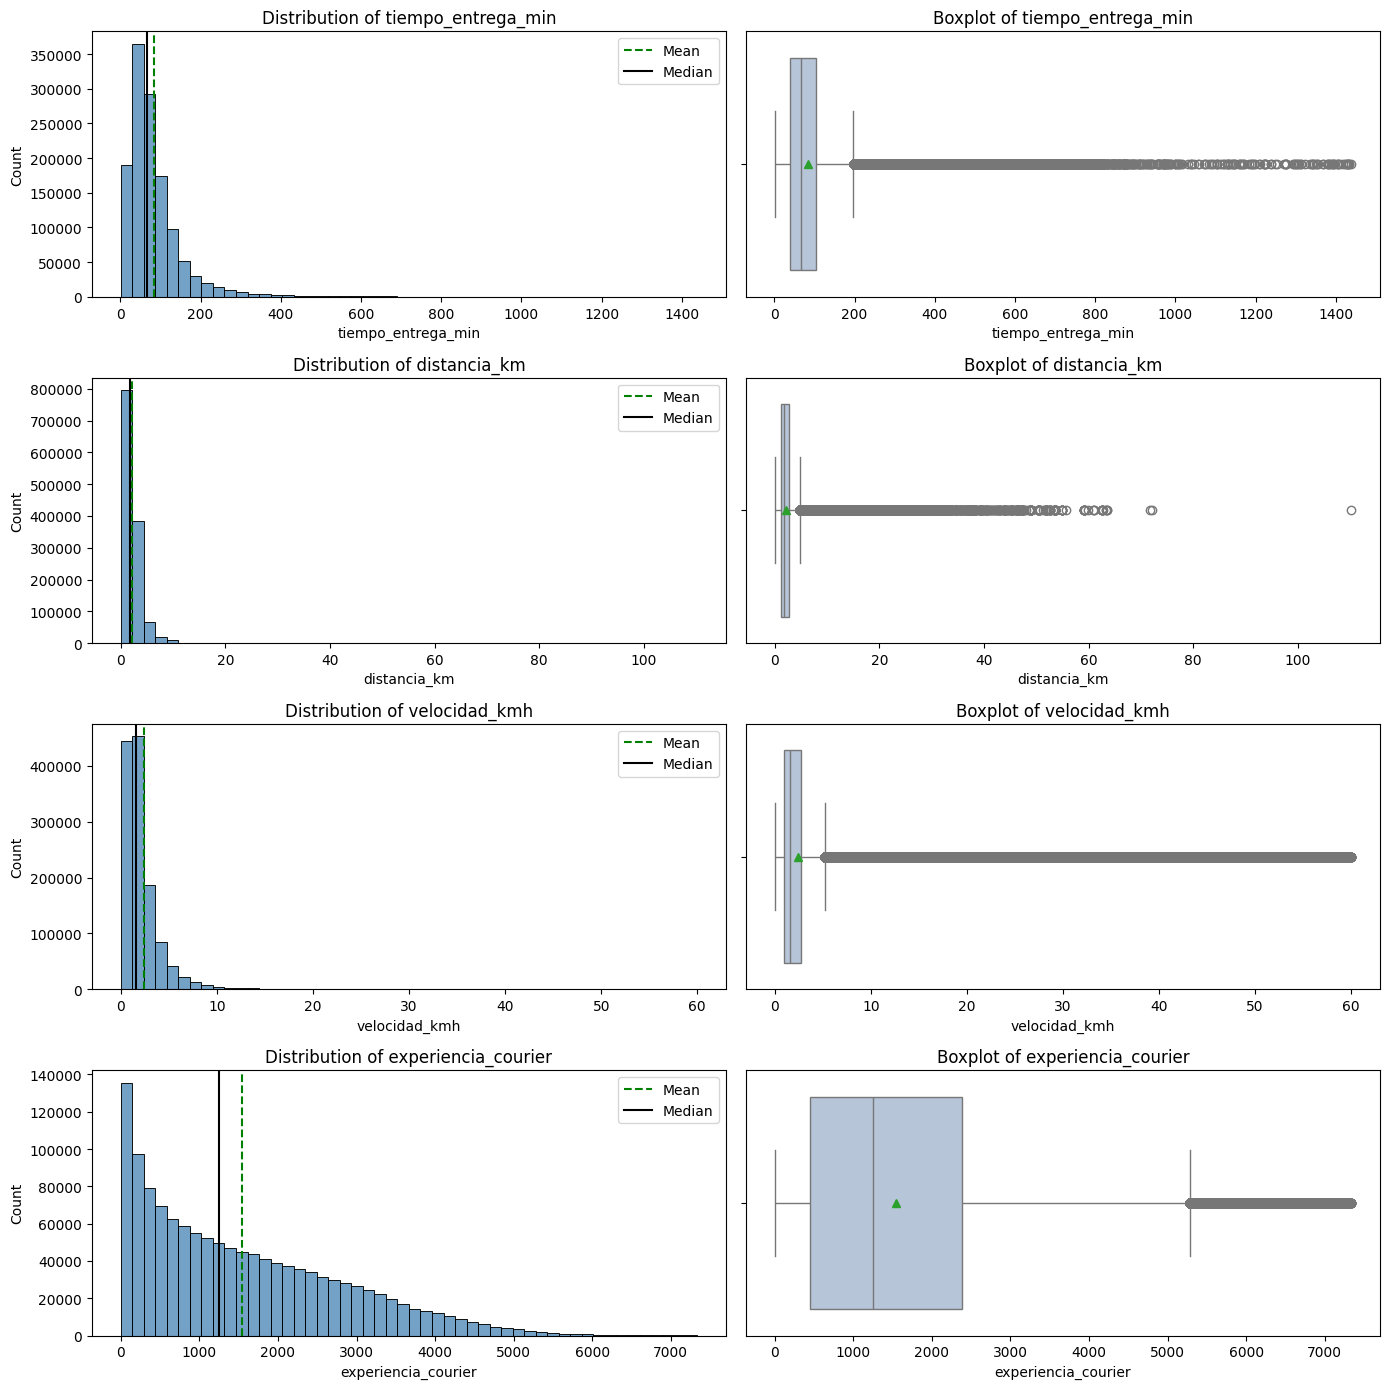

In [121]:
# Numerical variables: histogram (with mean and median) + boxplot side by side
num_cols = ['tiempo_entrega_min', 'distancia_km', 'velocidad_kmh', 'experiencia_courier']

fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 3.5 * len(num_cols)))

for i, col in enumerate(num_cols):
    # Histogram with mean and median lines
    sns.histplot(data=df_limpio, x=col, bins=50, ax=axes[i, 0], color="steelblue")
    axes[i, 0].axvline(df_limpio[col].mean(), color="green", linestyle="--", label="Mean")
    axes[i, 0].axvline(df_limpio[col].median(), color="black", linestyle="-", label="Median")
    axes[i, 0].set_title(f"Distribution of {col}")
    axes[i, 0].legend()

    # Boxplot (the triangle marks the mean)
    sns.boxplot(data=df_limpio, x=col, ax=axes[i, 1], color="lightsteelblue", showmeans=True)
    axes[i, 1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [122]:
# Statistical summary and skewness of the numerical variables (skewness > 1 means strongly right-skewed)
resumen_num = df_limpio[num_cols].describe().T
resumen_num['skewness'] = df_limpio[num_cols].skew()
resumen_num.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness
tiempo_entrega_min,1277452.0,84.87,76.59,1.0,40.00,66.00,103.00,1438.00,3.45
distancia_km,1277452.0,2.22,1.87,0.0,1.20,1.82,2.68,110.19,6.89
velocidad_kmh,1277452.0,2.41,3.48,0.0,0.99,1.60,2.69,59.99,8.27
experiencia_courier,1277452.0,1546.16,1276.15,0.0,455.00,1256.00,2386.00,7335.00,0.85


##### **Observations:**
<small><font color="gray">Numerical variables</font></small>

- **tiempo_entrega_min (target):** after cleaning, the median delivery time is 66 minutes and 50% of the orders are delivered between 40 and 103 minutes. The distribution is right-skewed (skewness 3.45), with a long tail of slow deliveries: 7.7% of the orders take more than 3 hours.
- **distancia_km:** the median distance is 1.8 km and 50% of the orders are between 1.2 and 2.7 km, which is consistent with last mile deliveries. It is strongly right-skewed (skewness 6.89), with a few extreme values of up to 110 km.
- **velocidad_kmh:** the median implied speed is only 1.6 km/h, and 25.7% of the orders are below 1 km/h. This shows that the delivery time is not only travel time: the courier carries several packages at once and delivers them along a route, so each order includes the time spent on other deliveries.
- **experiencia_courier:** it goes from 0 to 7,335 previous orders, with a median of 1,256. It is the least skewed variable (skewness 0.85), with many observations from couriers with little experience.

#### **Categorical variables**

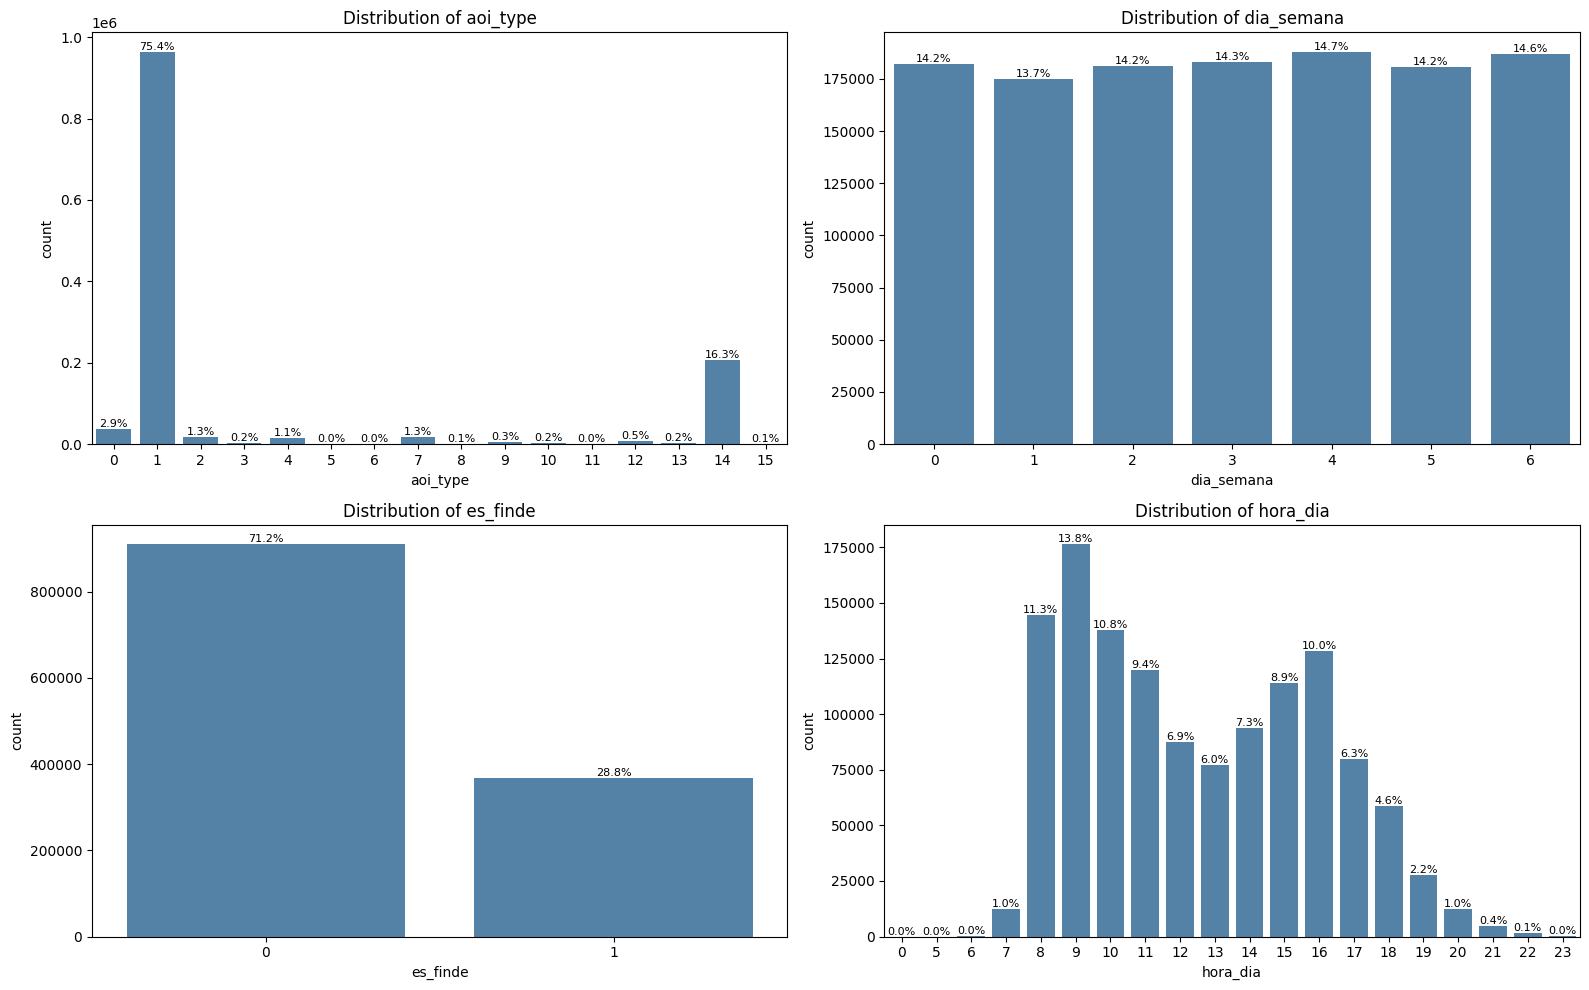

In [123]:
# Categorical and discrete variables: count plots with percentages
cat_cols = ['aoi_type', 'dia_semana', 'es_finde', 'hora_dia']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=df_limpio, x=col, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")

    # Annotate each bar with its percentage of orders
    for p in ax.patches:
        pct = 100 * p.get_height() / len(df_limpio)
        ax.annotate(f"{pct:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

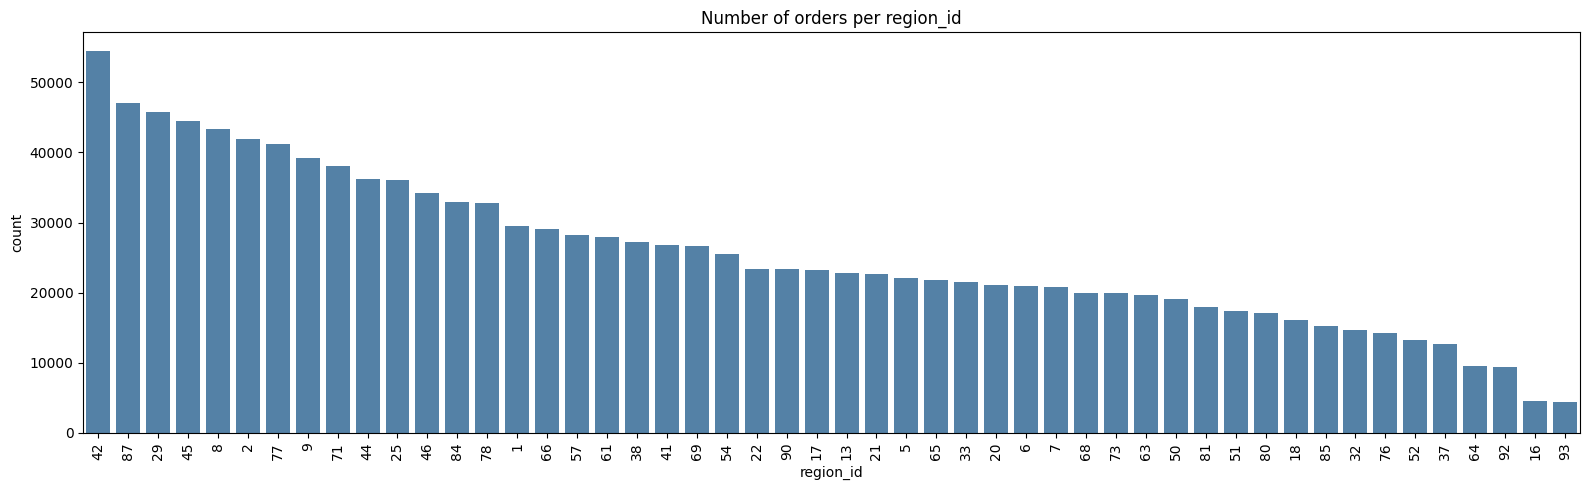

The top 10 regions concentrate 33.8% of the orders


In [124]:
# region_id has too many values for the grid above: count plot ordered by number of orders
plt.figure(figsize=(16, 5))
order = df_limpio['region_id'].value_counts().index
sns.countplot(data=df_limpio, x='region_id', order=order, color="steelblue")
plt.title("Number of orders per region_id")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Share of orders of the top 10 regions
top10 = df_limpio['region_id'].value_counts(normalize=True).head(10).sum() * 100
print(f"The top 10 regions concentrate {top10:.1f}% of the orders")

##### **Observations:**
<small><font color="gray">Categorical variables</font></small>

- **aoi_type:** it is very unbalanced. Type 1 concentrates 75.4% of the orders and type 14 another 16.3%. The other 14 types have less than 3% each.
- **dia_semana / es_finde:** orders are evenly distributed across the week (about 14% per day), so weekends represent 28.8% of the orders (2 out of 7 days). The operation works every day with a similar volume.
- **hora_dia:** almost all orders are accepted between 7 and 21 hs. There are two peaks: in the morning (9 hs, 13.8%) and in the afternoon (16 hs, 10.0%).
- **region_id:** after cleaning there are 50 regions (2 of the original 52 regions were completely removed by the filters). The volume varies a lot between regions, from about 4,300 to 54,400 orders, and the top 10 regions concentrate 33.8% of the orders.

### Bivariate Analysis

#### **Correlation between numerical variables**

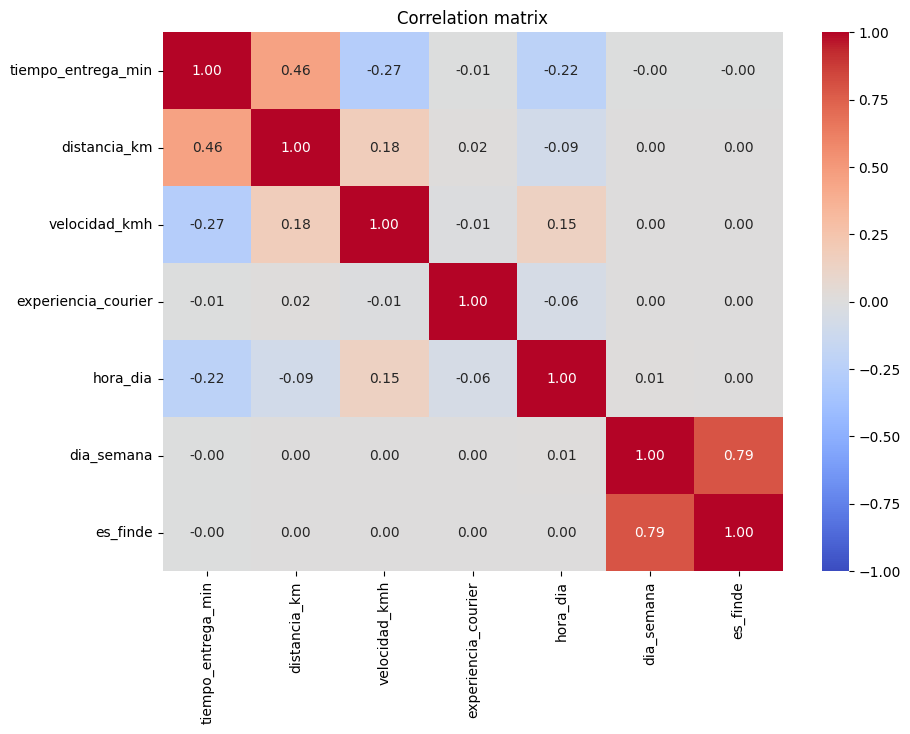

In [125]:
# Correlation heatmap of the numerical and time variables
corr_cols = num_cols + ['hora_dia', 'dia_semana', 'es_finde']

plt.figure(figsize=(10, 7))
sns.heatmap(df_limpio[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  

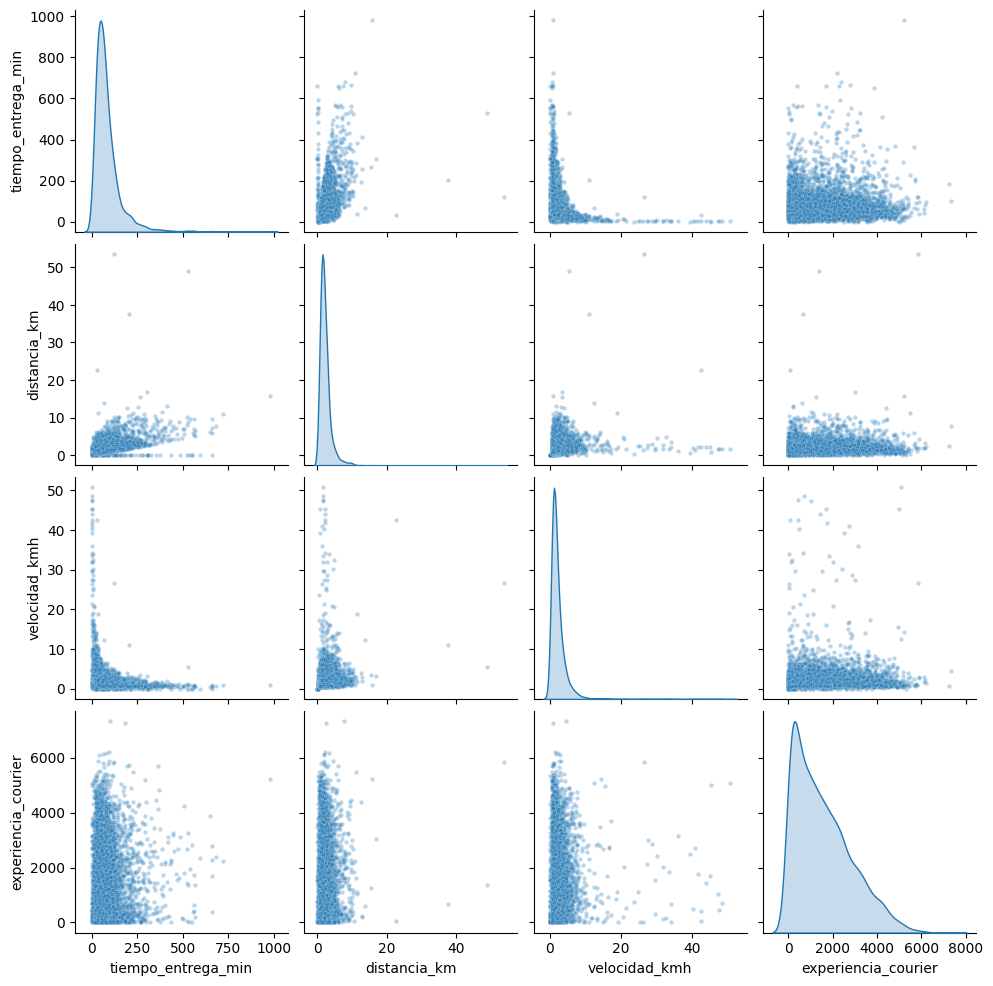

In [126]:
# Pairplot of the numerical variables
# We use a random sample of 5,000 orders, because plotting 1.2 million points is too slow
muestra = df_limpio[num_cols].sample(5000, random_state=42)

sns.pairplot(data=muestra, diag_kind="kde", plot_kws={"alpha": 0.3, "s": 10})
plt.show()

##### **Observations:**
<small><font color="gray">Correlation between numerical variables</font></small>

- `distancia_km` has the strongest correlation with the delivery time (0.46): the longer the distance, the longer the delivery.
- `hora_dia` has a negative correlation with the delivery time (-0.22): orders accepted later in the day are delivered faster.
- `velocidad_kmh` is correlated with the delivery time (-0.27), but it is calculated with the target, so we do not use it in the model.
- `experiencia_courier`, `dia_semana` and `es_finde` have practically no linear correlation with the delivery time (close to 0).
- `es_finde` is highly correlated with `dia_semana` (0.79), since it is derived from it.
- The pairplot shows that the relationships are weak and very dispersed. Even the relationship between distance and delivery time has a lot of noise. This anticipates that a linear model will have difficulty explaining the delivery time.

#### **Delivery time by categorical variable**

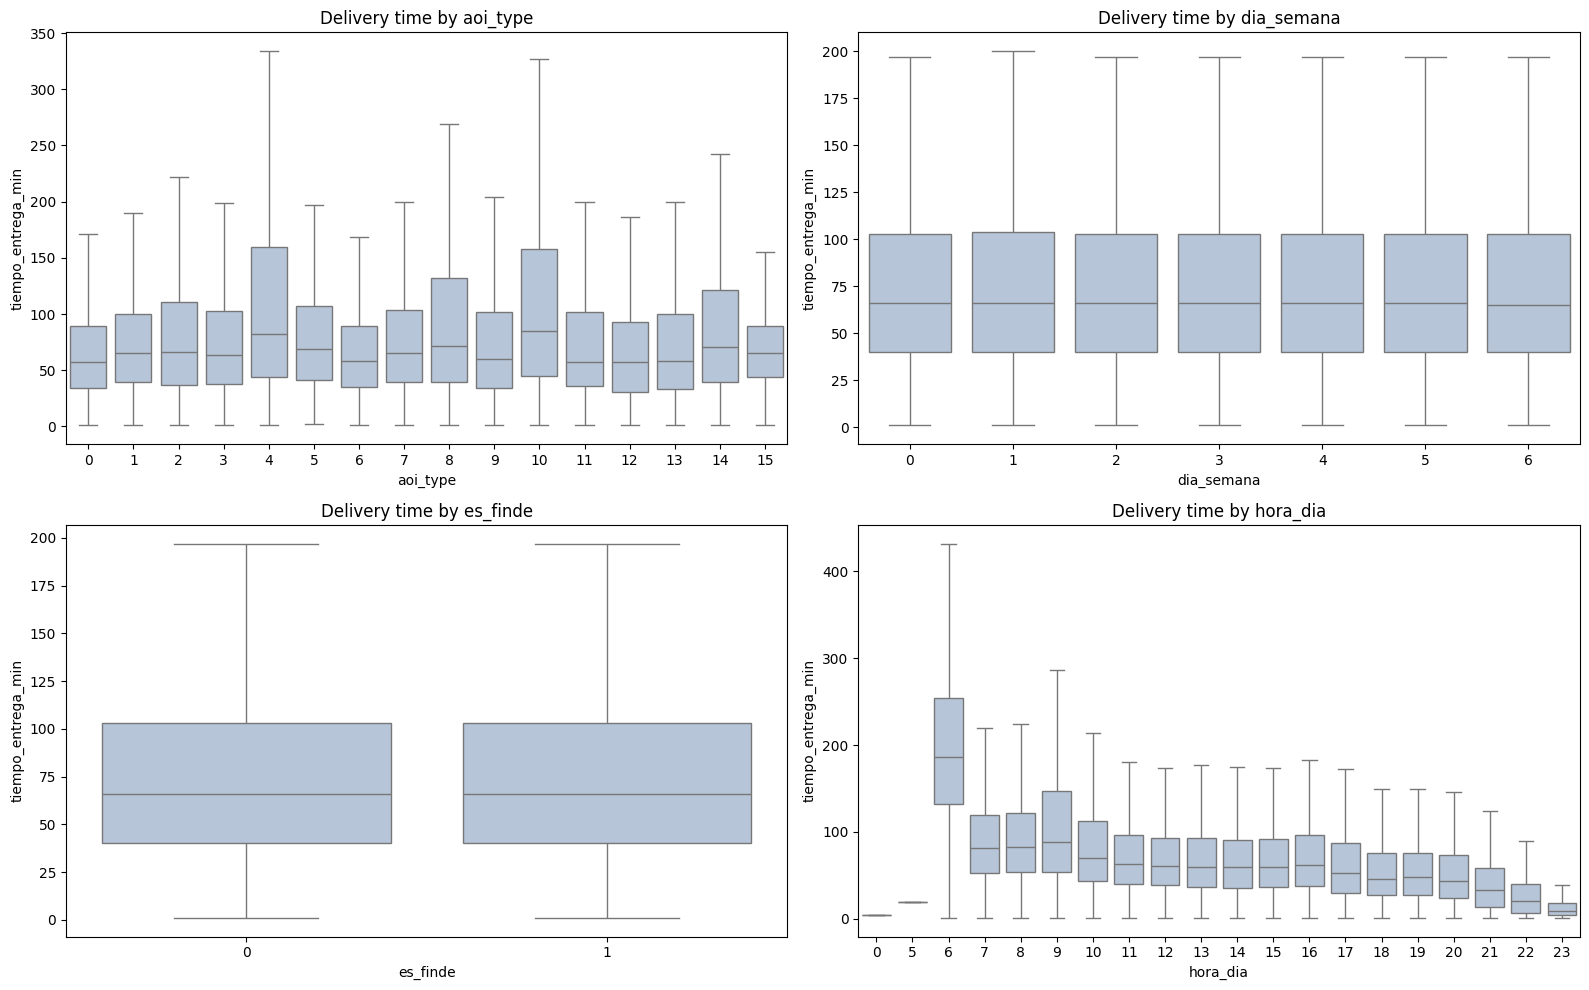

In [127]:
# Delivery time by categorical variable (outliers hidden to make the boxes readable)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, col in zip(axes.flatten(), cat_cols):
    sns.boxplot(data=df_limpio, x=col, y='tiempo_entrega_min', ax=ax, color="lightsteelblue", showfliers=False)
    ax.set_title(f"Delivery time by {col}")

plt.tight_layout()
plt.show()

In [128]:
# Median delivery time by category
for col in cat_cols:
    print(f"\nMedian delivery time (minutes) by {col}:")
    print(df_limpio.groupby(col)['tiempo_entrega_min'].median().round(1).to_string())


Median delivery time (minutes) by aoi_type:
aoi_type
0     57.0
1     65.0
2     66.0
3     64.0
4     82.0
5     69.0
6     58.0
7     65.0
8     72.0
9     60.0
10    85.0
11    57.0
12    57.0
13    58.0
14    71.0
15    65.0

Median delivery time (minutes) by dia_semana:
dia_semana
0    66.0
1    66.0
2    66.0
3    66.0
4    66.0
5    66.0
6    65.0

Median delivery time (minutes) by es_finde:
es_finde
0    66.0
1    66.0

Median delivery time (minutes) by hora_dia:
hora_dia
0       4.0
5      19.0
6     186.0
7      82.0
8      83.0
9      88.0
10     70.0
11     63.0
12     61.0
13     60.0
14     59.0
15     60.0
16     62.0
17     53.0
18     46.0
19     48.0
20     44.0
21     33.0
22     20.0
23      8.5


##### **Observations:**
<small><font color="gray">Delivery time by categorical variable</font></small>

- **hora_dia:** it is the categorical variable with the clearest effect. Orders accepted between 8 and 9 hs have a median of 83–88 minutes, while those accepted after 18 hs have a median below 50 minutes (20 minutes at 22 hs). This is consistent with couriers receiving many orders at the start of the shift and delivering them throughout the day.
- **aoi_type:** the medians go from 57 to 85 minutes. Types 4 and 10 are the slowest and have the highest dispersion. Type 14 (16% of the orders) is slower than type 1 (median 71 vs. 65 minutes).
- **dia_semana / es_finde:** the boxplots are identical and the median is 65–66 minutes every day. The day of the week does not affect the delivery time.
- In summary, the variables with the most potential to explain the delivery time are `distancia_km`, `hora_dia` and `aoi_type`. The day of the week does not add information.

## **Data Preprocessing**

Before building the model, we:
- Select the features (independent variables) and the target (dependent variable).
- Split the data into train and test, to evaluate the model on data it has not seen during training.
- Encode the categorical features with One-Hot Encoding.

#### **Feature selection**

In [129]:
# Columns excluded from the features, and why
columnas_a_excluir = [
    'order_id',            # unique identifier - no predictive value
    'courier_id',          # high cardinality (1,733 values) - does not generalize; its useful information is captured in experiencia_courier
    'aoi_id',              # very high cardinality (15,564 values) - not feasible for one-hot and does not generalize
    'ds',                  # redundant - date in MMDD format, already captured in hora_dia / dia_semana / es_finde
    'accept_time',         # raw timestamp, not usable as a number; already captured in hora_dia / dia_semana / es_finde
    'delivery_time',       # data leakage - actual delivery time, used to calculate the target
    'velocidad_kmh',       # data leakage - calculated with the target
    'tiempo_entrega_min',  # target (y), cannot be a feature (X)
    'lat',                 # multicollinearity - raw delivery coordinate, redundant with distancia_km
    'lng',                 # multicollinearity - same as lat
    'accept_gps_lat',      # multicollinearity - raw acceptance coordinate, redundant with distancia_km
    'accept_gps_lng',      # multicollinearity - same as accept_gps_lat
    'delivery_gps_lat',    # multicollinearity - raw delivery coordinate, redundant with distancia_km
    'delivery_gps_lng',    # multicollinearity - same as delivery_gps_lat
]

target_col = 'tiempo_entrega_min'
feature_cols = [c for c in df_limpio.columns if c not in columnas_a_excluir]

print("Final features:", feature_cols)

Final features: ['region_id', 'aoi_type', 'distancia_km', 'experiencia_courier', 'hora_dia', 'dia_semana', 'es_finde']


In [130]:
# Split the features into categorical and numerical
columnas_categoricas = ['region_id', 'aoi_type']
columnas_numericas = ['distancia_km', 'experiencia_courier', 'hora_dia', 'dia_semana', 'es_finde']

##### **Observations:**
<small><font color="gray">Feature selection</font></small>

- We keep 7 features: 2 categorical (`region_id`, `aoi_type`) and 5 numerical (`distancia_km`, `experiencia_courier`, `hora_dia`, `dia_semana`, `es_finde`).
- We exclude the identifiers with too many values (`order_id`, `courier_id`, `aoi_id`), the raw dates and coordinates (their information is already captured in the engineered features), and the variables that would cause data leakage (`delivery_time`, `velocidad_kmh`).
- `region_id` and `aoi_type` are numerical codes, but they represent categories, so we treat them as categorical.
- `hora_dia`, `dia_semana` and `es_finde` are kept as numerical variables.

#### **Train / test split**

In [131]:
# Split the data into train (80%) and test (20%)
X = df_limpio[columnas_categoricas + columnas_numericas]
y = df_limpio[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1021961, 7) Test: (255491, 7)


##### **Observations:**
<small><font color="gray">Train / test split</font></small>

- We use 80% of the data for training (1,021,961 orders) and 20% for testing (255,491 orders).
- We fix `random_state=42` so that the split is reproducible.
- **Limitation:** the split is random, but the data is temporal and orders come in groups (a courier accepts several orders at once and delivers them on the same route). Orders from the same courier, day and route can end up in both train and test, so the test metrics may be slightly optimistic. A temporal split (for example, training with May–September and testing with October) would better reflect how the model would be used to predict future orders.

#### **One-Hot Encoding**

In [132]:
# One-Hot Encoding of the categorical variables
# drop='first' removes the first category of each variable to avoid the dummy variable trap
# min_frequency groups the categories with less than 0.5% of the orders into a single 'infrequent' category
# dtype=np.uint8 stores the dummies as 0/1 integers, which uses 8 times less memory than float64
# The encoder is fitted ONLY with train, to avoid data leakage
encoder = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.005,
                        sparse_output=False, drop='first', dtype=np.uint8)
encoder.fit(X_train[columnas_categoricas])

X_train_ohe = encoder.transform(X_train[columnas_categoricas])
X_test_ohe = encoder.transform(X_test[columnas_categoricas])

nombres_ohe = encoder.get_feature_names_out(columnas_categoricas)

X_train_ohe_df = pd.DataFrame(X_train_ohe, columns=nombres_ohe, index=X_train.index)
X_test_ohe_df = pd.DataFrame(X_test_ohe, columns=nombres_ohe, index=X_test.index)

In [133]:
# Final datasets: numerical variables + dummies
X_train_final = pd.concat([X_train[columnas_numericas], X_train_ohe_df], axis=1)
X_test_final = pd.concat([X_test[columnas_numericas], X_test_ohe_df], axis=1)

print(X_train_final.shape, X_test_final.shape)
X_train_final.head()

(1021961, 60) (255491, 60)


,distancia_km,experiencia_courier,hora_dia,dia_semana,es_finde,region_id_2,region_id_5,region_id_6,region_id_7,region_id_8,...,region_id_90,region_id_92,region_id_infrequent_sklearn,aoi_type_1,aoi_type_2,aoi_type_4,aoi_type_7,aoi_type_12,aoi_type_14,aoi_type_infrequent_sklearn
1409435,2.939014,2180,19,1,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
869736,7.964760,1899,15,3,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
445023,1.120435,447,10,2,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1040997,2.365556,2343,13,1,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
252234,4.631233,352,9,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [134]:
# Sanity check of the final datasets
# There should be no missing values after the encoding
print(f"Missing values in train: {X_train_final.isnull().sum().sum()}")
print(f"Missing values in test: {X_test_final.isnull().sum().sum()}")

# Train and test must have exactly the same columns, in the same order
print(f"Same columns in train and test: {list(X_train_final.columns) == list(X_test_final.columns)}")

Missing values in train: 0
Missing values in test: 0
Same columns in train and test: True


##### **Observations:**
<small><font color="gray">One-Hot Encoding</font></small>

- The encoder is fitted only with the train data and then applied to train and test, so no information from the test set is used during training.
- We drop the first category of each variable (`drop='first'`) to avoid the dummy variable trap, which would cause perfect multicollinearity in the linear regression. The reference categories are region 1 and AOI type 0.
- Categories with less than 0.5% of the orders are grouped into a single `infrequent` category, because with so few observations their coefficients would be unstable:
    - `aoi_type`: 9 rare types (1.1% of the orders) are grouped, so it generates 6 dummies plus `aoi_type_infrequent_sklearn`.
    - `region_id`: regions 16 and 93 are grouped, so it generates 48 dummies.
- The dummies are stored as `uint8` (0/1), which reduces the memory of the train set from about 560 MB to about 100 MB.
- The final datasets have 60 columns: 5 numerical variables + 55 dummies.
- There are no missing values, and train and test have the same columns in the same order.

## **Model Building**

We test **3 regression models** to predict the delivery time (`tiempo_entrega_min`) and compare their metrics:

| # | Model | Type | Why we test it |
| :--- | :--- | :--- | :--- |
| 1 | **Linear Regression** | Linear model | Baseline: simple and interpretable |
| 2 | **Gradient Boosting** | Ensemble of trees (boosting) | Each tree corrects the errors of the previous ones |
| 3 | **Random Forest** | Ensemble of trees (bagging) | Captures non-linear relationships and interactions between variables |

**Process for each model:**
1. **Linear Regression:** we check multicollinearity (VIF), train the model, evaluate it on test and analyze the residuals.
2. **Gradient Boosting and Random Forest:**
    - **Cross validation (K-Fold, 5 folds)** on a sample of 15,000 orders of train, to check the stability of the model.
    - **Final training** with the full train set and **evaluation** on test.
    - **Hyperparameter tuning** with `RandomizedSearchCV` on the same sample, and evaluation of the tuned model on test.
3. **Model comparison** on the test set.

**Metrics:**
- **RMSE** (Root Mean Squared Error): average error in minutes, penalizing large errors more.
- **MAE** (Mean Absolute Error): average absolute error in minutes. It is the easiest to interpret.
- **R² and Adjusted R²:** share of the variability of the delivery time explained by the model.
- **MAPE** (Mean Absolute Percentage Error): average error as a percentage of the real value. It works best when there are no values close to 0, which is not our case (there are deliveries of a few minutes).

In [135]:
# Function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# Function to compute MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# Function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    pred = model.predict(predictors)                  # Predict using the independent variables
    r2 = r2_score(target, pred)                       # To compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)    # To compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # To compute RMSE
    mae = mean_absolute_error(target, pred)           # To compute MAE
    mape = mape_score(target, pred)                   # To compute MAPE

    # Creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

### **Model 1: Linear Regression**

#### **Checking for multicollinearity (VIF)**

**Multicollinearity** occurs when the independent variables are highly correlated with each other, so they do not provide unique information. In that case, it becomes difficult for the model to estimate the effect of each variable on the target.

The **Variance Inflation Factor (VIF)** measures how much the variance of a coefficient is inflated by multicollinearity. Usually, features with a VIF greater than 5 are treated or dropped.

Calculating the VIF on the full train set (1 million orders) takes too long, so we calculate it on a random sample of 50,000 orders, which gives practically the same result.

In [136]:
def checking_vif(train):
    vif = pd.DataFrame()
    vif["feature"] = train.columns

    # Calculating VIF for each feature
    vif["VIF"] = [
        variance_inflation_factor(train.values, i) for i in range(len(train.columns))
    ]
    return vif

In [137]:
# VIF on a sample of 50,000 orders of train (on the full train set it takes too long)
# The constant is added so that the VIF is calculated correctly, and then removed from the results
X_vif = sm.add_constant(X_train_final.sample(50000, random_state=42).astype(float))

vif_resultado = checking_vif(X_vif)
vif_resultado = vif_resultado[vif_resultado['feature'] != 'const'].sort_values('VIF', ascending=False)
vif_resultado.head(10)

,feature,VIF
54,aoi_type_1,7.048807
59,aoi_type_14,6.046519
25,region_id_42,2.842894
5,es_finde,2.654052
4,dia_semana,2.653518
19,region_id_29,2.464399
50,region_id_87,2.444432
11,region_id_9,2.393089
10,region_id_8,2.383067
6,region_id_2,2.382624


##### **Observations:**
<small><font color="gray">Checking for multicollinearity (VIF)</font></small>

- Only `aoi_type_1` (7.0) and `aoi_type_14` (6.0) have a VIF greater than 5. Together they represent 92% of the orders, so they are almost complementary: when an order is not type 1, it is very likely type 14. It is a consequence of the encoding (the reference category, type 0, is small), not a real problem of the data.
- `dia_semana` and `es_finde` have a VIF of 2.7, which is acceptable even though `es_finde` is derived from `dia_semana`.
- The rest of the variables have a VIF below 3, so there is no relevant multicollinearity and we keep all the features.

#### **Training and evaluation**

In [138]:
from sklearn.linear_model import  LinearRegression
#https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

modelo = LinearRegression()
help(modelo)

Help on LinearRegression in module sklearn.linear_model._base object:

class LinearRegression(sklearn.base.MultiOutputMixin, sklearn.base.RegressorMixin, LinearModel)
 |  LinearRegression(*, fit_intercept=True, copy_X=True, n_jobs=None, positive=False)
 |  
 |  Ordinary least squares Linear Regression.
 |  
 |  LinearRegression fits a linear model with coefficients w = (w1, ..., wp)
 |  to minimize the residual sum of squares between the observed targets in
 |  the dataset, and the targets predicted by the linear approximation.
 |  
 |  Parameters
 |  ----------
 |  fit_intercept : bool, default=True
 |      Whether to calculate the intercept for this model. If set
 |      to False, no intercept will be used in calculations
 |      (i.e. data is expected to be centered).
 |  
 |  copy_X : bool, default=True
 |      If True, X will be copied; else, it may be overwritten.
 |  
 |  n_jobs : int, default=None
 |      The number of jobs to use for the computation. This will only provide
 | 

In [139]:
modelo.fit(X_train_final, y_train) #<<< entrenamiento

LinearRegression()

In [140]:
#Una vez entrenado el modelo está listo para usarlo.
y_pred  = modelo.predict(X_test_final)
# Los métodos predict siempre devuelven un numpy array

/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [141]:
df_y_pred = pd.Series(y_pred)
df_y_pred
# Ya siendo una serie podemos explorar los resultados

0          80.662771
1          74.294553
2          47.860339
3          84.449644
4          78.028955
             ...    
255486     94.687696
255487    153.948856
255488     46.446722
255489     47.366126
255490     89.575342
Length: 255491, dtype: float64

In [142]:
# Crear una copia de X_test_final para no modificar la variable original
test = X_test_final.copy()

# Asignar los valores predichos y los valores reales alineando sus arreglos
test['pred'] = y_pred
test['real'] = y_test.values

# Visualizar el DataFrame final
test

,distancia_km,experiencia_courier,hora_dia,dia_semana,es_finde,region_id_2,region_id_5,region_id_6,region_id_7,region_id_8,...,region_id_infrequent_sklearn,aoi_type_1,aoi_type_2,aoi_type_4,aoi_type_7,aoi_type_12,aoi_type_14,aoi_type_infrequent_sklearn,pred,real
1369969,3.115018,136,12,2,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,80.662771,143.0
60641,1.541661,1014,12,2,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,74.294553,53.0
1326209,0.369513,1957,9,3,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,47.860339,20.0
417342,2.310384,178,11,6,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,84.449644,66.0
838964,1.452258,759,8,3,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,78.028955,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257397,2.357353,4029,11,5,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,94.687696,22.0
773600,3.028807,3177,9,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,153.948856,209.0
543204,0.582789,746,15,4,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,46.446722,53.0
1325673,0.700866,580,11,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,47.366126,53.0


#### **Distributions and residuals**

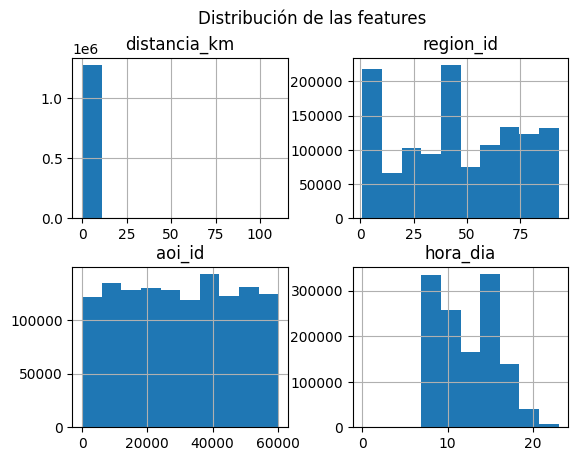

In [143]:
# Definir la variable 'datos' seleccionando las columnas de interés de tu DataFrame
datos = df_limpio[['distancia_km', 'region_id', 'aoi_id', 'hora_dia']]

# Cambiar 'features' para usar los nombres de las columnas en lugar de un rango numérico
features = datos.columns

# Generar el histograma
datos[features].hist()
plt.suptitle("Distribución de las features")
plt.show()

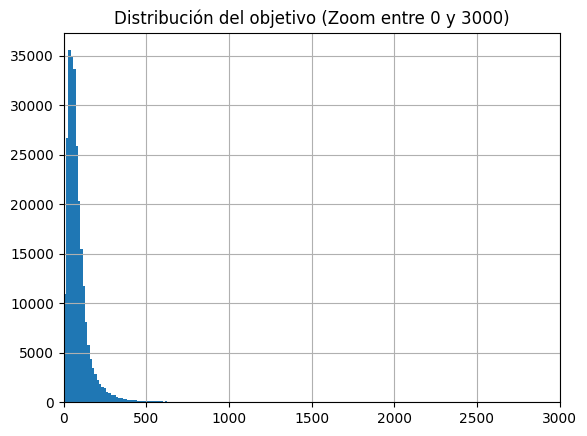

In [144]:
# Aumentamos los intervalos y filtramos el rango visual del eje X
y_test.hist(bins=100)
plt.xlim(0, 3000)  # Ajusta el límite según la zona de interés
plt.title("Distribución del objetivo (Zoom entre 0 y 3000)")
plt.show()

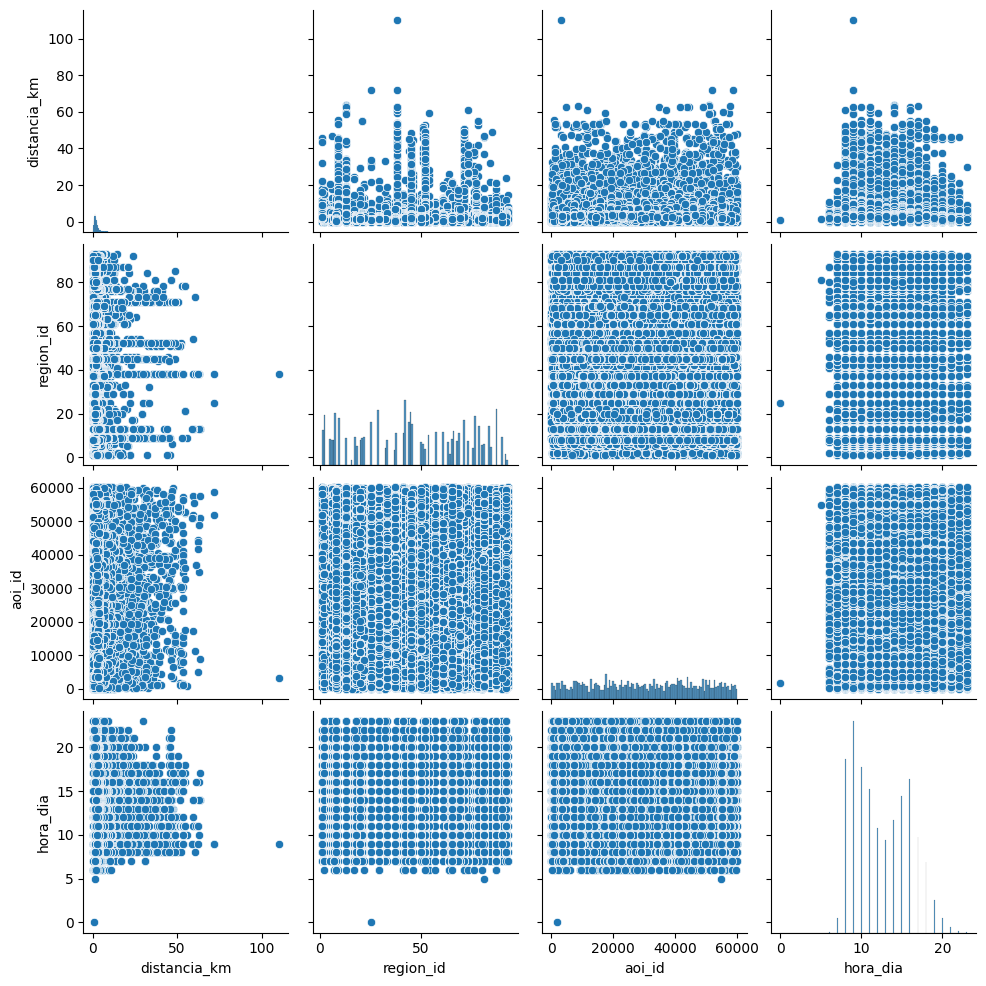

In [145]:
sns.pairplot(datos, diag_kind="hist")
plt.show()

/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


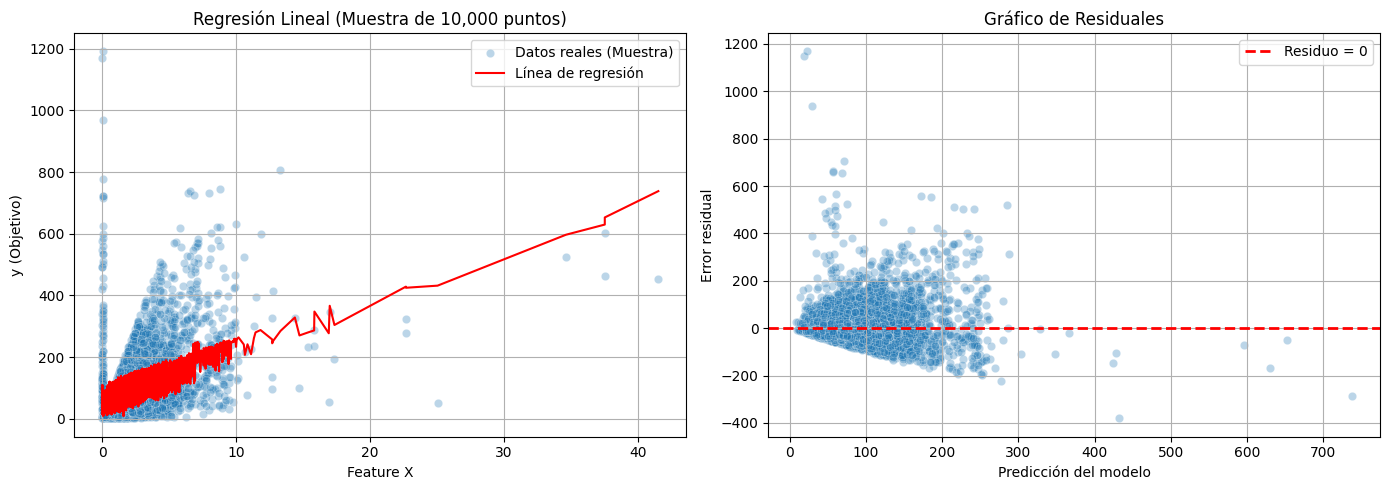

In [146]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

# 1. Entrenar el modelo con los datos completos
modelo = LinearRegression()
modelo.fit(X_train_final, y_train)

# 2. Tomar una muestra aleatoria razonable para graficar (10,000 puntos)
tamano_muestra = min(10000, len(X_test_final))

# Asegurar muestreo consistente tanto si es DataFrame/Series como si es NumPy array
if hasattr(X_test_final, "sample"):
    idx_muestra = X_test_final.sample(n=tamano_muestra, random_state=42).index
    X_test_sub = X_test_final.loc[idx_muestra]
    y_test_sub = y_test.loc[idx_muestra]
else:
    np.random.seed(42)
    idx_muestra = np.random.choice(len(X_test_final), size=tamano_muestra, replace=False)
    X_test_sub = X_test_final[idx_muestra]
    y_test_sub = y_test[idx_muestra]

# 3. Predicciones y cálculo de residuales sobre la muestra
y_pred_sub = modelo.predict(X_test_sub)
y_real_sub = y_test_sub.values if hasattr(y_test_sub, "values") else y_test_sub
residuales_sub = y_real_sub.flatten() - y_pred_sub.flatten()

# Seleccionar la primera feature para el eje X del primer gráfico
if hasattr(X_test_sub, "iloc"):
    x_graf = X_test_sub.iloc[:, 0].values
else:
    x_graf = X_test_sub[:, 0]

# 4. Crear subplots
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# --- Subplot 1: Gráfico de regresión (Muestra con alpha para evitar superposición) ---
sns.scatterplot(
    x=x_graf, y=y_real_sub.flatten(), ax=axs[0], alpha=0.3, label='Datos reales (Muestra)'
)
sns.lineplot(
    x=x_graf, y=y_pred_sub.flatten(), color='red', ax=axs[0], label='Línea de regresión'
)
axs[0].set_title(f'Regresión Lineal (Muestra de {tamano_muestra:,} puntos)')
axs[0].set_xlabel('Feature X')
axs[0].set_ylabel('y (Objetivo)')
axs[0].legend()
axs[0].grid(True)

# --- Subplot 2: Gráfico de residuales ---
sns.scatterplot(x=y_pred_sub.flatten(), y=residuales_sub, ax=axs[1], alpha=0.3)
axs[1].axhline(0, color='red', linestyle='--', linewidth=2, label='Residuo = 0')
axs[1].set_title('Gráfico de Residuales')
axs[1].set_xlabel('Predicción del modelo')
axs[1].set_ylabel('Error residual')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

#### **Metrics**

In [147]:
from sklearn.metrics import mean_absolute_percentage_error

# Calcular el MAPE
error_mape = mean_absolute_percentage_error(y_test, y_pred)
print(error_mape)

0.9662230418097898


In [148]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Error Absoluto Medio (MAE) -> en las mismas unidades de tu variable
mae = mean_absolute_error(y_test, y_pred)

# Raíz del Error Cuadrático Medio (RMSE)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 41.3871
RMSE: 65.0873


##### **Observations:**
<small><font color="gray">Linear Regression</font></small>

- The linear regression explains only 28.7% of the variability of the delivery time (R² on test 0.287).
- The average error is 41.4 minutes (MAE) and the RMSE is 65.1 minutes, which is high considering that the median delivery time is 66 minutes.
- The residual plot shows that the errors are not randomly distributed around 0: the model underestimates the long deliveries (large positive residuals) and its predictions concentrate in a narrow range. The relationship between the variables and the delivery time is not linear, as we saw in the EDA.
- The MAPE (0.97, that is 97%) is very high because of the short deliveries: an error of 20 minutes on a delivery of 5 minutes is a 400% error.

### **Model 2: Gradient Boosting**

#### **Base model and cross validation**

In [149]:
#  ---------------------------------------------------------------------------------------------------------------GradientBoostingRegressor INIT
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# 3\. Instanciar el modelo de Gradient Boosting y la estrategia de K-Fold
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html
modelo_gb_reg = GradientBoostingRegressor()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [150]:
# Achico el dataset para las estadisticas de cross validation.
# despues del paso 3, previo al paso 4
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train_final, y_train, train_size=15000,
    random_state=42)
# 4\. VALIDACIÓN CRUZADA (K-Fold) DENTRO DE TRAIN (Antes del fit definitivo)
# Evaluamos la estabilidad y el rendimiento general SOLO sobre X_train_sample, y_train_sample
cv_results = cross_validate( modelo_gb_reg, X_train_sample, y_train_sample, cv=kf, scoring=['r2', 'neg_mean_absolute_error'] )

In [151]:
r2_cross_v = cv_results['test_r2'].mean()
mae_cross_v = -cv_results['test_neg_mean_absolute_error'].mean()
print("=== 1º VALIDACIÓN CRUZADA (Sobre conjunto Train Sample) ===")
print(f"R² promedio en K-Fold: {r2_cross_v}")
print(f"MAE promedio en K-Fold: {mae_cross_v}")

=== 1º VALIDACIÓN CRUZADA (Sobre conjunto Train Sample) ===
R² promedio en K-Fold: 0.38602408592249604
MAE promedio en K-Fold: 38.96309018855463


In [152]:
# 5. ENTRENAMIENTO DEFINITIVO (Una vez validada la configuración)
# Se entrena el modelo final usando el 100% de X_train_final, y_train
modelo_gb_reg.fit(X_train_final, y_train)

# 6. EVALUACIÓN FINAL SOBRE TEST (Datos nunca antes vistos)
y_pred = modelo_gb_reg.predict(X_test_final)

r2_base = r2_score(y_test, y_pred)
mae_base= mean_absolute_error(y_test, y_pred)
print("\n=== 2º EVALUACIÓN FINAL (Sobre conjunto Test Completo) ===")
print(f"R² en Test: {r2_base}")
print(f"MAE en Test: {mae_base}")


=== 2º EVALUACIÓN FINAL (Sobre conjunto Test Completo) ===
R² en Test: 0.41465823755214226
MAE en Test: 38.795207148380634


In [153]:
#Métrica para comparar modelos: R2
print(f"R² base: {r2_base:.4f}")
print(f"MAE base: {mae_base:.2f}")
print(f"R² cross-v: {r2_cross_v:.4f}")
print(f"MAE cross-v: {mae_cross_v:.2f}")

# parametros actuales por defecto todo ( n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42 )

R² base: 0.4147
MAE base: 38.80
R² cross-v: 0.3860
MAE cross-v: 38.96


##### **Observations:**
<small><font color="gray">Gradient Boosting – Base model</font></small>

- In the cross validation on the sample of 15,000 orders, the average R² is 0.39 and the MAE is 38.9 minutes.
- Trained with the full train set, the model reaches an R² of 0.41 and an MAE of 38.8 minutes on test, clearly better than the linear regression.
- The results on the sample and on test are similar, so the model is stable. With the default hyperparameters (100 trees of depth 3), it is a simple model.

#### **Hyperparameter tuning**

In [154]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV

# 1. Distribución de búsqueda de hiperparámetros
param_dist = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.1],
    "max_depth": [1,3, 4],
    "max_features": ["sqrt", "log2"],
}

# 2. Definir el modelo base y K-Fold
gb = GradientBoostingRegressor(
    random_state=42
)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Configurar la búsqueda aleatoria
search = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_dist,
    n_iter=20,              # Número de combinaciones aleatorias
    scoring="r2",           # Métrica a maximizar
    cv=kf,
    random_state=42,
    n_jobs=-1,              # Utiliza todos los núcleos disponibles
    verbose=1
)

# 4. Ajustar sobre la submuestra de entrenamiento
# Por ejemplo, X_train_sample e y_train_sample pueden contener 50.000 filas
search.fit(X_train_sample, y_train_sample)

# 5. Mostrar los mejores resultados
print(f"Mejor R² en K-Fold: {search.best_score_:.4f}")

print("Mejores hiperparámetros encontrados:")
for param, value in search.best_params_.items():
    print(f" - {param}: {value}")

# 6. Obtener el mejor modelo entrenado
best_model = search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Mejor R² en K-Fold: 0.3870
Mejores hiperparámetros encontrados:
 - n_estimators: 300
 - max_features: sqrt
 - max_depth: 4
 - learning_rate: 0.1


In [155]:
# RESULTADO
#Fitting 5 folds for each of 20 candidates, totalling 100 fits
#Mejor R² en K-Fold: 0.2718
#Mejores hiperparámetros encontrados:
# - n_estimators: 200
# - max_features: sqrt
# - max_depth: 4
# - learning_rate: 0.1

In [156]:
# 5. ENTRENAMIENTO DEFINITIVO (Una vez validada la configuración)
# Se entrena el modelo final usando el 100% de X_train_final, y_train
#https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html
modelo_gb_reg_v2 = GradientBoostingRegressor( n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42,max_features= 'sqrt' )
kf = KFold(n_splits=5, shuffle=True, random_state=42)

modelo_gb_reg_v2.fit(X_train_final, y_train)

# 6. EVALUACIÓN FINAL SOBRE TEST (Datos nunca antes vistos)
y_pred_v2 = modelo_gb_reg_v2.predict(X_test_final)


print("\n=== 2º EVALUACIÓN FINAL (Sobre conjunto Test) ===")
print(f"MAE en Test: {mean_absolute_error(y_test, y_pred_v2):.2f}")
print(f"R² en Test: {r2_score(y_test, y_pred_v2):.4f}")


=== 2º EVALUACIÓN FINAL (Sobre conjunto Test) ===
MAE en Test: 38.63
R² en Test: 0.4194


In [157]:
#Métrica para comparar modelos: R2
r2_rs = r2_score(y_test, y_pred_v2)
mae_rs= mean_absolute_error(y_test, y_pred_v2)
#Métrica para comparar modelos: R2
print(f"R² base: {r2_base:.4f}")
print(f"MAE base: {mae_base:.2f}")
print(f"R² cross-v: {r2_cross_v:.4f}")
print(f"MAE cross-v: {mae_cross_v:.2f}")
print(f"R² RandomizedSearchCV: {r2_rs:.4f}")
print(f"MAE cross-v: {mae_rs:.2f}")

R² base: 0.4147
MAE base: 38.80
R² cross-v: 0.3860
MAE cross-v: 38.96
R² RandomizedSearchCV: 0.4194
MAE cross-v: 38.63


Text(0.5, 1.0, 'Comparacion R2 modelo GradientBoostingRegressor')

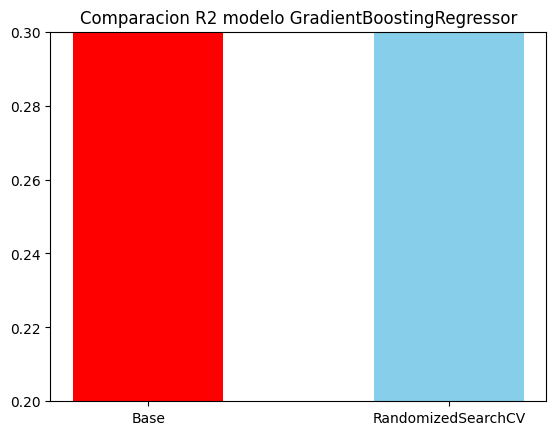

In [158]:
plt.bar(x=['Base','RandomizedSearchCV'],height=[r2_base,r2_rs],width=0.5,color=['red','skyblue'])
plt.ylim(bottom=0.20,top = 0.3)
plt.title('Comparacion R2 modelo GradientBoostingRegressor')

##### **Observations:**
<small><font color="gray">Gradient Boosting – Hyperparameter tuning</font></small>

- The search finds as best hyperparameters `n_estimators=300`, `learning_rate=0.1`, `max_depth=4` and `max_features='sqrt'` (R² in K-Fold 0.387).
- The final model is trained with the hyperparameters of the original search (`n_estimators=200`), and improves slightly on test: R² from 0.415 to 0.419 and MAE from 38.8 to 38.6 minutes.
- The improvement from the tuning is small: the limit is in the information available in the features, not in the hyperparameters.

### **Model 3: Random Forest**

#### **Base model and cross validation**

In [159]:
# =========================================================================
# RandomForestRegressor - Modelo final (Sil)
# Tener en cuanta que deben existir previamente: X_train_final, X_test_final, y_train, y_test (celda 24 del notebook)
# =========================================================================

# ---- Instanciar modelo base + K-Fold ----
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# min_samples_leaf=10 y max_samples=0.3 limitan el tamaño de los árboles: sin ellos, cada árbol ocupa ~90 MB
# con 1 millón de pedidos (~9 GB para 100 árboles), más que la memoria disponible en Colab
modelo_rf_reg = RandomForestRegressor(random_state=42, n_jobs=-1, min_samples_leaf=10, max_samples=0.3)
kf = KFold(n_splits=5, shuffle=True, random_state=42) #Copiar el mismo que la celda 21 para que sean iguales

In [160]:
# ---- Validación cruzada (K-Fold) dentro de train ---- Ramdom Forest
# Usamos la misma muestra reducida que usaron para GB, para que la comparación sea justa
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train_final, y_train, train_size=15000, random_state=42
)

cv_results_rf = cross_validate(
    modelo_rf_reg, X_train_sample, y_train_sample,
    cv=kf, scoring=['r2', 'neg_mean_absolute_error']
)

r2_cross_v_rf = cv_results_rf['test_r2'].mean()
mae_cross_v_rf = -cv_results_rf['test_neg_mean_absolute_error'].mean()

print("=== VALIDACIÓN CRUZADA - RandomForest (sobre Train Sample) ===")
print(f"R² promedio en K-Fold: {r2_cross_v_rf:.4f}")
print(f"MAE promedio en K-Fold: {mae_cross_v_rf:.2f}")

=== VALIDACIÓN CRUZADA - RandomForest (sobre Train Sample) ===
R² promedio en K-Fold: 0.3617
MAE promedio en K-Fold: 39.51


In [161]:
# ---- Entrenamiento definitivo + evaluación en test ----Ramdom Forest
modelo_rf_reg.fit(X_train_final, y_train)
y_pred_rf = modelo_rf_reg.predict(X_test_final)

r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("\n=== EVALUACIÓN FINAL - RandomForest (sobre Test completo) ===")
print(f"R² en Test: {r2_rf:.4f}")
print(f"MAE en Test: {mae_rf:.2f}")
print(f"RMSE en Test: {rmse_rf:.2f}")


=== EVALUACIÓN FINAL - RandomForest (sobre Test completo) ===
R² en Test: 0.5325
MAE en Test: 34.60
RMSE en Test: 52.69


##### **Observations:**
<small><font color="gray">Random Forest – Base model</font></small>

- In the cross validation on the sample, the average R² is 0.36 and the MAE is 39.5 minutes, slightly worse than Gradient Boosting on the same sample.
- However, trained with the full train set, it reaches an R² of 0.53 and an MAE of 34.6 minutes on test. It is the best result so far: it almost doubles the R² of the linear regression.
- The big improvement between the sample and the full train set shows that Random Forest benefits a lot from having more data.
- The R² on train (0.59) is a bit higher than on test (0.53), so there is some overfitting, but it is moderate.

#### **Hyperparameter tuning**

In [162]:
# ---- Búsqueda de hiperparámetros ---- Ramdom Forest
from sklearn.model_selection import RandomizedSearchCV

param_dist_rf = {
    "n_estimators": [200, 300, 500],
    "max_depth": [8, 12, 15, 20, None],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

search_rf = RandomizedSearchCV(
    rf_base,
    param_distributions=param_dist_rf,
    n_iter=15,
    cv=kf,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
search_rf.fit(X_train_sample, y_train_sample)

print("Mejores hiperparámetros encontrados:", search_rf.best_params_) #esto me va a dar una lista, que tengo que colocar de nuevo en el código,
# volver al paso de la definicióm del modelo

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Mejores hiperparámetros encontrados: {'n_estimators': 500, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 12}


In [163]:
# ---- Entrenar versión optimizada y comparar ---- Ramdom Forest
modelo_rf_reg_v2 = RandomForestRegressor(**search_rf.best_params_, random_state=42, n_jobs=-1)
modelo_rf_reg_v2.fit(X_train_final, y_train)
y_pred_rf_v2 = modelo_rf_reg_v2.predict(X_test_final)

r2_rf_v2 = r2_score(y_test, y_pred_rf_v2)
mae_rf_v2 = mean_absolute_error(y_test, y_pred_rf_v2)

print("\n=== Comparación final de modelos ===")
print(f"R² base:               {r2_base:.4f}   (GradientBoosting)")
print(f"R² RandomForest:       {r2_rf:.4f}")
print(f"R² RandomForest (RS):  {r2_rf_v2:.4f}")
print(f"MAE base:              {mae_base:.2f}   (GradientBoosting)")
print(f"MAE RandomForest:      {mae_rf:.2f}")
print(f"MAE RandomForest (RS): {mae_rf_v2:.2f}")


=== Comparación final de modelos ===
R² base:               0.4147   (GradientBoosting)
R² RandomForest:       0.5325
R² RandomForest (RS):  0.4725
MAE base:              38.80   (GradientBoosting)
MAE RandomForest:      34.60
MAE RandomForest (RS): 37.33


##### **Observations:**
<small><font color="gray">Random Forest – Hyperparameter tuning</font></small>

- The best hyperparameters found are `n_estimators=500`, `max_depth=12`, `min_samples_leaf=5` and `max_features=0.5`.
- However, the tuned model performs worse on test than the base model (R² 0.47 vs. 0.53, MAE 37.3 vs. 34.6 minutes).
- The search was done on a sample of 15,000 orders, where shallower trees (`max_depth=12`) work better. With 1 million orders, deeper trees can learn more patterns, so the hyperparameters chosen on the sample do not transfer well to the full dataset.

### **Model comparison**

In [164]:
# Comparison of the models on the test set
comparacion = pd.concat([
    model_performance_regression(modelo, X_test_final, y_test),
    model_performance_regression(modelo_gb_reg, X_test_final, y_test),
    model_performance_regression(modelo_gb_reg_v2, X_test_final, y_test),
    model_performance_regression(modelo_rf_reg, X_test_final, y_test),
    model_performance_regression(modelo_rf_reg_v2, X_test_final, y_test),
])
comparacion.index = ["Linear Regression", "Gradient Boosting", "Gradient Boosting (tuned)",
                     "Random Forest", "Random Forest (tuned)"]
comparacion.round(3)

/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/miniconda3/envs/mit-env/lib/python3.11/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
Linear Regression,65.087,41.387,0.287,0.287,96.622
Gradient Boosting,58.960,38.795,0.415,0.415,95.551
Gradient Boosting (tuned),58.721,38.631,0.419,0.419,95.580
Random Forest,52.692,34.600,0.533,0.532,83.781
Random Forest (tuned),55.971,37.326,0.473,0.472,91.221


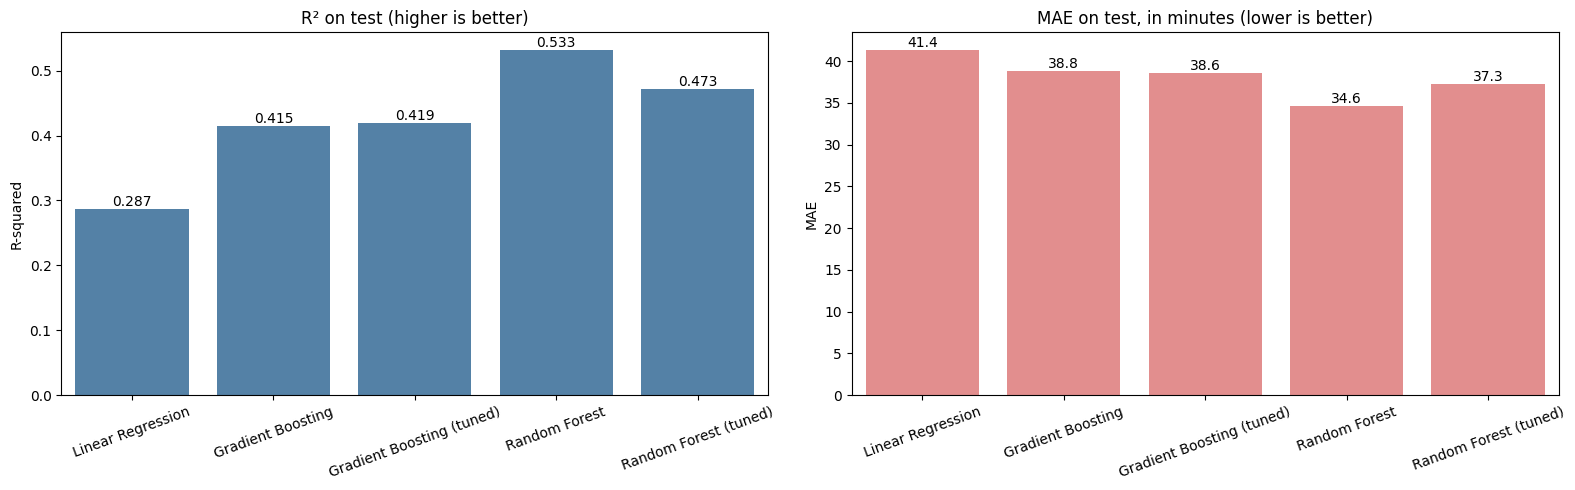

In [165]:
# R² and MAE of each model on the test set
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x=comparacion.index, y=comparacion["R-squared"], ax=axes[0], color="steelblue")
axes[0].set_title("R² on test (higher is better)")
axes[0].bar_label(axes[0].containers[0], fmt="%.3f")

sns.barplot(x=comparacion.index, y=comparacion["MAE"], ax=axes[1], color="lightcoral")
axes[1].set_title("MAE on test, in minutes (lower is better)")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

##### **Observations:**
<small><font color="gray">Model comparison</font></small>

- **The best model is the Random Forest base model**, with an R² of 0.53 and an MAE of 34.6 minutes on test.
- Both tree-based models clearly outperform the linear regression (R² 0.29, MAE 41.4 minutes), which confirms that the relationship between the variables and the delivery time is not linear.
- The hyperparameter tuning on a sample of 15,000 orders improved Gradient Boosting slightly, but made Random Forest worse. With such a large dataset, the hyperparameters should be searched on a larger sample.
- Even the best model leaves almost half of the variability unexplained, with an average error of about 35 minutes. Part of the delivery time depends on factors that are not in the dataset, such as the order in which the courier delivers the packages of the route, traffic or waiting time at the destination.
- The MAPE is high in all the models (84–97%) because of the short deliveries, so we use the MAE and the R² to compare them.